# Inside the Backward Pass

**iCog Labs Internship Capstone**

Derive a small network’s backward pass, implement it in NumPy, and verify the gradients with finite differences. Train a linear baseline and a nonlinear network on XOR.

## 1. Phase 1 · Manual mathematical derivation and numerical trace

Use a single row vector $x=(1,-2)$ and target $y=0.8$. A weight's row indexes its source and its column indexes its destination. Biases are row vectors.

$$
W_1=\begin{bmatrix}0.4&-0.3\\0.1&0.2\end{bmatrix},\quad
b_1=(0.1,0.2),\quad
W_2=\begin{bmatrix}0.7\\-0.5\end{bmatrix},\quad b_2=0.1.
$$

### Forward pass

The first affine transformation is $z_1=xW_1+b_1$. Each column of $W_1$ supplies the two weights for one hidden neuron.

$$
\begin{aligned}
z_{1,1}&=(1)(0.4)+(-2)(0.1)+0.1=0.3,\\
z_{1,2}&=(1)(-0.3)+(-2)(0.2)+0.2=-0.5,\\
h_1&=\sigma(0.3)=\frac{1}{1+e^{-0.3}}\approx0.574442517,\\
h_2&=\sigma(-0.5)=\frac{1}{1+e^{0.5}}\approx0.377540669.
\end{aligned}
$$

The output neuron is linear. With one scalar prediction, the mean squared error has a single term.

$$
\begin{aligned}
\hat y&=hW_2+b_2=(0.574442517)(0.7)+(0.377540669)(-0.5)+0.1
       \approx0.313339427,\\
r&=\hat y-y\approx-0.486660573,\\
L&=(\hat y-y)^2\approx0.236838513.
\end{aligned}
$$

### Backward through the loss and output neuron

Write $g_q=\partial L/\partial q$. The square contributes $2r$ and $\partial r/\partial\hat y=1$, so $g_{\hat y}=2r\approx-0.973321145$.

In $\hat y=\sum_j h_jW_{2,j1}+b_2$, varying $W_{2,j1}$ changes $\hat y$ at rate $h_j$. Varying $h_j$ changes it at rate $W_{2,j1}$. The coefficient of $b_2$ is $1$. Multiplying each local derivative by $g_{\hat y}$ gives

$$
\begin{aligned}
g_{W_{2,j1}}&=g_{\hat y}h_j,&
g_{W_2}&\approx(-0.559117048,-0.367468316)^\top,\\
g_{b_2}&=g_{\hat y}(1),&
g_{b_2}&\approx-0.973321145,\\
g_{h_j}&=g_{\hat y}W_{2,j1},&
g_h&\approx(-0.681324802,\phantom{-}0.486660573).
\end{aligned}
$$

### Backward through sigmoid and the first affine transformation

Differentiating the reciprocal $(1+e^{-z})^{-1}$ gives a factor $-(1+e^{-z})^{-2}$. Differentiating its inner term gives $-e^{-z}$. The negatives cancel, and the numerator can be expressed using $\sigma(z)$.

$$
\sigma'(z)=\frac{e^{-z}}{(1+e^{-z})^2}
=\frac{1}{1+e^{-z}}\left(1-\frac{1}{1+e^{-z}}\right)
=\sigma(z)(1-\sigma(z)).
$$

Each activation depends on its own pre-activation. Apply that local derivative to the gradient arriving from the output.

$$
\begin{aligned}
g_{z_{1,1}}&=(-0.681324802)(0.244458312)\approx-0.166555511,\\
g_{z_{1,2}}&=(\phantom{-}0.486660573)(0.235003712)\approx\phantom{-}0.114367041.
\end{aligned}
$$

For $z_{1,j}=\sum_i x_iW_{1,ij}+b_{1,j}$, the local derivatives with respect to $W_{1,ij}$, $b_{1,j}$, and $x_i$ are $x_i$, $1$, and $W_{1,ij}$, respectively. Each weight and bias affects one pre-activation. Each input affects both, so its path contributions add.

$$
\begin{aligned}
g_{W_1}&=x^\top g_{z_1}
=\begin{bmatrix}1\\-2\end{bmatrix}
  \begin{bmatrix}-0.166555511&0.114367041\end{bmatrix}
\approx\begin{bmatrix}-0.166555511&0.114367041\\0.333111021&-0.228734082\end{bmatrix},\\
g_{b_1}&=g_{z_1}\approx(-0.166555511,\ 0.114367041),\\
g_{x_1}&=(-0.166555511)(0.4)+(0.114367041)(-0.3)\approx-0.100932317,\\
g_{x_2}&=(-0.166555511)(0.1)+(0.114367041)(0.2)\approx\phantom{-}0.006217857.
\end{aligned}
$$

For example, $W_{1,21}$ has a path through hidden neuron 1. The product along it is $g_{\hat y}(0.7)(0.244458312)(-2)\approx0.333111021$.

### Reference values

Entries in matrices are listed by row. The trace uses full-precision intermediate values before rounding for display.

| Quantity | Components |
|---|---|
| $x$ and $y$ | $(1,-2)$ and $0.8$ |
| $z_1$ | $(0.300000000000,\ -0.500000000000)$ |
| $h$ | $(0.574442516812,\ 0.377540668798)$ |
| Output pre-activation $z_2=\hat y$ | $0.313339427369$ |
| Residual $r$ | $-0.486660572631$ |
| Loss $L$ | $0.236838512953$ |
| $g_{\hat y}$ | $-0.973321145262$ |
| $g_{W_2}$ | $(-0.559117048350;\ -0.367468316138)$ |
| $g_{b_2}$ | $-0.973321145262$ |
| $g_h$ | $(-0.681324801683,\ 0.486660572631)$ |
| Local $\sigma'(z_1)$ | $(0.244458311691,\ 0.235003712202)$ |
| $g_{z_1}$ and $g_{b_1}$ | $(-0.166555510733,\ 0.114367041150)$ |
| $g_{W_1}$ | $(-0.166555510733,\ 0.114367041150;\ 0.333111021465,\ -0.228734082301)$ |
| $g_x$ | $(-0.100932316638,\ 0.006217857157)$ |

## 2. Phase 2 · Linear layer

For a batch of $N$ rows, $X\in\mathbb R^{N\times D}$, $W\in\mathbb R^{D\times K}$ and $b\in\mathbb R^{1\times K}$. The layer returns $Z=XW+b$ with shape $(N,K)$ and caches $X$ for the backward pass. NumPy broadcasts $b$ across rows.

The **upstream gradient** $G=\partial L/\partial Z$ has one entry per output. It measures how the final loss changes when a layer output changes. From the scalar derivatives above,

$$
\begin{aligned}
(g_W)_{ij}&=\sum_n X_{ni}G_{nj} \quad\Rightarrow\quad g_W=X^\top G,\\
(g_b)_{1j}&=\sum_n G_{nj},\\
(g_X)_{ni}&=\sum_j G_{nj}W_{ij} \quad\Rightarrow\quad g_X=GW^\top.
\end{aligned}
$$

The transpose on $W$ gives a $(K,D)$ matrix that maps each row of $K$ output sensitivities back to $D$ inputs. The sums account for every place a shared weight or bias was used. The loss supplies the averaging factor.

In [1]:
import numpy as np


class Linear:
    def __init__(self, in_features, out_features, rng=None):
        rng = np.random.default_rng() if rng is None else rng
        scale = np.sqrt(2 / (in_features + out_features))
        self.W = rng.normal(0, scale, (in_features, out_features))
        self.b = np.zeros((1, out_features))
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, upstream_grad):
        self.dW = self.x.T @ upstream_grad
        self.db = upstream_grad.sum(axis=0, keepdims=True)
        return upstream_grad @ self.W.T

With $X=\begin{bmatrix}2&-1\\0&3\end{bmatrix}$, $W=(0.4,-0.2)^\top$ and $b=0.1$, the two outputs are $2(0.4)+(-1)(-0.2)+0.1=1.1$ and $0(0.4)+3(-0.2)+0.1=-0.5$. If the next operation sends $G=(0.5,-0.25)^\top$, the first weight receives $2(0.5)+0(-0.25)=1$ and the second receives $(-1)(0.5)+3(-0.25)=-1.25$. The bias receives $0.5-0.25=0.25$. The input gradients are the rows $0.5(0.4,-0.2)$ and $-0.25(0.4,-0.2)$.

In [2]:
linear_demo = Linear(2, 1, np.random.default_rng(1))
linear_demo.W[:] = [[0.4], [-0.2]]
linear_demo.b[:] = 0.1
demo_x = np.array([[2.0, -1.0], [0.0, 3.0]])
demo_z = linear_demo.forward(demo_x)
demo_dx = linear_demo.backward(np.array([[0.5], [-0.25]]))

print(f"Z   {demo_z.ravel()}")
print(f"dW  {linear_demo.dW.ravel()}")
print(f"db  {linear_demo.db.ravel()}")
print(f"dX  {demo_dx.tolist()}")

Z   [ 1.1 -0.5]
dW  [ 1.   -1.25]
db  [0.25]
dX  [[0.2, -0.1], [-0.1, 0.05]]


## 3. Activation layers

Each activation entry depends only on its matching input. Multiply each upstream gradient by that entry’s local derivative.

- **Sigmoid.** The Phase 1 derivation gives $h(1-h)$. Cache $h$. Compute the forward pass with $t=e^{-|z|}$ and choose $1/(1+t)$ for $z\ge0$ or $t/(1+t)$ for $z<0$. The exponent is always nonpositive.
- **ReLU.** $\max(0,z)$ is constant below zero and has slope $1$ above zero. At the kink, this engine selects the subgradient $0$. Cache the positive mask.
- **Tanh.** Since $\tanh z=\sinh z/\cosh z$, the quotient rule gives $(\cosh^2 z-\sinh^2 z)/\cosh^2 z=1-\tanh^2 z$. Cache the output.

In [3]:
class Sigmoid:
    def forward(self, x):
        exp_term = np.exp(-np.abs(x))
        denominator = 1 + exp_term
        self.output = np.where(x >= 0, 1 / denominator, exp_term / denominator)
        return self.output

    def backward(self, upstream_grad):
        return upstream_grad * self.output * (1 - self.output)


class ReLU:
    def forward(self, x):
        self.positive = x > 0
        return np.maximum(0, x)

    def backward(self, upstream_grad):
        return upstream_grad * self.positive


class Tanh:
    def forward(self, x):
        self.output = np.tanh(x)
        return self.output

    def backward(self, upstream_grad):
        return upstream_grad * (1 - self.output**2)

## 4. Loss functions

Both losses take predictions and targets with the same nonempty shape $(N,K)$. They average over **all** $M=NK$ entries. Binary targets are $0$ or $1$ and BCE predictions are sigmoid probabilities.

$$
L_{\mathrm{MSE}}=\frac{1}{M}\sum_i(\hat y_i-y_i)^2,
\qquad \frac{\partial L_{\mathrm{MSE}}}{\partial\hat y_i}
=\frac{2(\hat y_i-y_i)}{M}.
$$

For BCE, let $q_i=\operatorname{clip}(p_i,\varepsilon,1-\varepsilon)$ with $\varepsilon=10^{-12}$. Differentiating the two logarithms gives the two terms below. The clip has slope $1$ in its open interval and $0$ outside. At either clipping kink, use the zero convention.

$$
\begin{aligned}
L_{\mathrm{BCE}}&=-\frac{1}{M}\sum_i[y_i\log q_i+(1-y_i)\log(1-q_i)],\\
\frac{\partial L_{\mathrm{BCE}}}{\partial p_i}
&=\frac{1}{M}\left(-\frac{y_i}{q_i}+\frac{1-y_i}{1-q_i}\right)
  \frac{\partial q_i}{\partial p_i}.
\end{aligned}
$$

Clipping keeps both logarithms finite at probabilities $0$ and $1$. For the second term, `log1p(-q)` computes $\log(1-q)$ accurately even for small $q$. Within the clip interval, multiplying the probability gradient by the sigmoid derivative also gives the logit gradient $(p_i-y_i)/M$.

In [4]:
class MSELoss:
    def forward(self, prediction, target):
        if prediction.shape != target.shape or prediction.size == 0:
            raise ValueError("Prediction and target must have the same nonempty shape.")
        self.residual = prediction - target
        return np.mean(self.residual**2)

    def backward(self, upstream_grad=1.0):
        return upstream_grad * 2 * self.residual / self.residual.size


class BCELoss:
    def __init__(self, epsilon=1e-12):
        if not np.finfo(float).eps <= epsilon < 0.5:
            raise ValueError("epsilon must be at least float64 precision and below 0.5.")
        self.epsilon = epsilon

    def forward(self, prediction, target):
        if prediction.shape != target.shape or prediction.size == 0:
            raise ValueError("Prediction and target must have the same nonempty shape.")
        p = np.asarray(prediction, dtype=np.float64)
        self.target = target
        self.q = np.clip(p, self.epsilon, 1 - self.epsilon)
        self.inside = (p > self.epsilon) & (p < 1 - self.epsilon)
        return -np.mean(target * np.log(self.q) + (1 - target) * np.log1p(-self.q))

    def backward(self, upstream_grad=1.0):
        dq = -self.target / self.q + (1 - self.target) / (1 - self.q)
        return upstream_grad * dq * self.inside / self.q.size

## 5. Network implementation

The network feeds each layer's output to its successor. Backward starts with the loss gradient and visits the same layers in reverse order. The loss lives outside the network so the same engine can run regression and classification. Parameter arrays are returned by reference, which lets the checker perturb a single entry and lets gradient descent update arrays in place.

In [5]:
class Network:
    def __init__(self, *layers):
        self.layers = layers

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, upstream_grad):
        for layer in reversed(self.layers):
            upstream_grad = layer.backward(upstream_grad)
        return upstream_grad

    def parameters_and_grads(self):
        for index, layer in enumerate(self.layers, start=1):
            if isinstance(layer, Linear):
                yield f"layer{index}.W", layer.W, layer.dW
                yield f"layer{index}.b", layer.b, layer.db

## 6. Compare the mathematical trace with the engine

Run the fixed example layer by layer to expose the intermediate values. The engine’s combined forward and backward calls must agree with the trace. Compare the result with the independent Phase 1 values rounded to 12 decimal places.

In [6]:
def phase1_network():
    rng = np.random.default_rng(2)
    first, last = Linear(2, 2, rng), Linear(2, 1, rng)
    first.W[:] = [[0.4, -0.3], [0.1, 0.2]]
    first.b[:] = [0.1, 0.2]
    last.W[:] = [[0.7], [-0.5]]
    last.b[:] = 0.1
    return Network(first, Sigmoid(), last)


x_fixed, y_fixed = np.array([[1.0, -2.0]]), np.array([[0.8]])
trace_net = phase1_network()
first, sigmoid, last = trace_net.layers
mse = MSELoss()

z1 = first.forward(x_fixed)
hidden = sigmoid.forward(z1)
prediction = last.forward(hidden)
loss_value = mse.forward(prediction, y_fixed)
d_prediction = mse.backward()
d_hidden = last.backward(d_prediction)
d_z1 = sigmoid.backward(d_hidden)
d_input = first.backward(d_z1)
np.testing.assert_allclose(trace_net.forward(x_fixed), prediction, rtol=0, atol=1e-14)
np.testing.assert_allclose(trace_net.backward(d_prediction), d_input, rtol=0, atol=1e-14)

In [7]:
trace = [
    ("z1", [0.3, -0.5], z1),
    ("h", [0.574442516812, 0.377540668798], hidden),
    ("prediction", [0.313339427369], prediction),
    ("residual", [-0.486660572631], mse.residual),
    ("loss", [0.236838512953], loss_value),
    ("d_prediction", [-0.973321145262], d_prediction),
    ("dW2", [-0.559117048350, -0.367468316138], last.dW),
    ("db2", [-0.973321145262], last.db),
    ("d_hidden", [-0.681324801683, 0.486660572631], d_hidden),
    ("sigmoid slope", [0.244458311691, 0.235003712202],
     sigmoid.backward(np.ones_like(hidden))),
    ("d_z1", [-0.166555510733, 0.114367041150], d_z1),
    ("dW1", [-0.166555510733, 0.114367041150, 0.333111021465, -0.228734082301],
     first.dW),
    ("db1", [-0.166555510733, 0.114367041150], first.db),
    ("d_input", [-0.100932316638, 0.006217857157], d_input),
]

max_trace_error = 0.0
print(f"{'Component':<22} {'Reference':>17} {'Engine':>17} {'Abs. diff.':>10}")
for name, reference, actual in trace:
    actual = np.asarray(actual)
    reference = np.reshape(reference, actual.shape)
    errors = np.abs(reference - actual)
    assert np.all(np.isfinite(errors)), f"Non-finite trace result for {name}."
    max_trace_error = max(max_trace_error, errors.max())
    for index in np.ndindex(actual.shape):
        label = f"{name}{index}" if actual.size > 1 else name
        print(f"{label:<22} {reference[index]:17.12f} "
              f"{actual[index]:17.12f} {errors[index]:10.2e}")

assert max_trace_error <= 5.01e-13, "Phase 1 trace exceeds its rounding tolerance."
print(f"\nPASS | Maximum absolute difference {max_trace_error:.2e}")

Component                      Reference            Engine Abs. diff.
z1(0, 0)                  0.300000000000    0.300000000000   5.55e-17
z1(0, 1)                 -0.500000000000   -0.500000000000   5.55e-17
h(0, 0)                   0.574442516812    0.574442516812   3.41e-13
h(0, 1)                   0.377540668798    0.377540668798   1.45e-13
prediction                0.313339427369    0.313339427369   8.86e-14
residual                 -0.486660572631   -0.486660572631   8.85e-14
loss                      0.236838512953    0.236838512953   4.47e-13
d_prediction             -0.973321145262   -0.973321145262   1.77e-13
dW2(0, 0)                -0.559117048350   -0.559117048350   2.08e-13
dW2(1, 0)                -0.367468316138   -0.367468316138   4.75e-13
db2                      -0.973321145262   -0.973321145262   1.77e-13
d_hidden(0, 0)           -0.681324801683   -0.681324801683   2.76e-13
d_hidden(0, 1)            0.486660572631    0.486660572631   8.85e-14
sigmoid slope(0, 0) 

Rounding a full-precision value to 12 decimal places introduces at most $5\times10^{-13}$ of absolute error. The trace assertion allows a small floating-point margin on top of that bound.

## 7. Phase 3 · Numerical gradient checking

For each scalar parameter $\theta_i$, hold all other parameters fixed and evaluate the full forward loss at $\theta_i+\delta$ and $\theta_i-\delta$ with $\delta=10^{-5}$.

$$
g_i^{\mathrm{num}}=
\frac{L(\theta_i+\delta)-L(\theta_i-\delta)}{2\delta}.
$$

The symmetric estimate uses only forward calls. Comparing it with backpropagation checks derivative signs, matrix orientation, and loss scaling at the tested points.

The per-coordinate relative error is $|g_i-g_i^{\mathrm{num}}|/\max(10^{-4},|g_i|,|g_i^{\mathrm{num}}|)$. For derivatives near zero the floor turns the $10^{-6}$ threshold into an absolute tolerance of $10^{-10}$. Every coordinate must be finite and below the threshold. ReLU kinks and BCE clipping kinks are tested by their selected conventions because a central difference across a kink combines two one-sided slopes.

In [8]:
GRAD_TOLERANCE = 1e-6


def central_difference(values, evaluate, step=1e-5):
    numerical = np.empty_like(values, dtype=float)
    for index in np.ndindex(values.shape):
        original = values[index]
        try:
            values[index] = original + step
            high = evaluate()
            values[index] = original - step
            low = evaluate()
        finally:
            values[index] = original
        numerical[index] = (high - low) / (2 * step)
    return numerical


def gradient_error(analytical, numerical):
    scale = np.maximum(1e-4, np.maximum(np.abs(analytical), np.abs(numerical)))
    return np.abs(analytical - numerical) / scale


def gradient_check(network, loss, x, y):
    def evaluate():
        return loss.forward(network.forward(x), y)

    evaluate()
    network.backward(loss.backward())
    results = {}
    print("Relative errors in parameter array order")
    print(f"{'Array':<13} {'Entries':>7} {'Max rel. error':>16}  Status")
    for name, parameter, gradient in network.parameters_and_grads():
        numerical = central_difference(parameter, evaluate)
        errors = gradient_error(gradient, numerical)
        results[name] = errors
        passed = bool(np.all(errors < GRAD_TOLERANCE))
        print(f"{name:<13} {parameter.size:7d} {errors.max():16.2e}  "
              f"{'PASS' if passed else 'FAIL'}")
        for row in errors:
            print("  " + "  ".join(f"{error:.2e}" for error in row))

    # Synchronize caches and gradients with the restored parameters.
    evaluate()
    network.backward(loss.backward())
    passed = all(np.all(errors < GRAD_TOLERANCE) for errors in results.values())
    print(f"Overall {'PASS' if passed else 'FAIL'} (threshold {GRAD_TOLERANCE:.0e})")
    assert passed
    return results

In [9]:
print("Fixed sigmoid network with MSE")
fixed_checks = gradient_check(phase1_network(), MSELoss(), x_fixed, y_fixed)

check_rng = np.random.default_rng(12)
batch_net = Network(Linear(2, 3, check_rng), ReLU(), Linear(3, 2, check_rng), Sigmoid())
batch_x = np.array([[0.2, -0.8], [-0.7, 0.4], [0.9, 0.3]])
batch_y = np.array([[0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
batch_first = batch_net.layers[0]
batch_z = batch_first.forward(batch_x)
assert np.min(np.abs(batch_z)) > 1e-4
assert batch_z.min() < 0 < batch_z.max()

print("\nBatched ReLU network with two BCE outputs per sample")
batch_checks = gradient_check(batch_net, BCELoss(), batch_x, batch_y)

Fixed sigmoid network with MSE
Relative errors in parameter array order
Array         Entries   Max rel. error  Status
layer1.W            4         2.45e-11  PASS
  2.03e-11  7.79e-12
  2.45e-11  1.65e-11
layer1.b            2         2.03e-11  PASS
  2.03e-11  1.65e-11
layer3.W            2         9.02e-12  PASS
  7.54e-12
  9.02e-12
layer3.b            1         1.07e-13  PASS
  1.07e-13
Overall PASS (threshold 1e-06)

Batched ReLU network with two BCE outputs per sample
Relative errors in parameter array order
Array         Entries   Max rel. error  Status
layer1.W            6         3.94e-10  PASS
  8.78e-12  2.79e-11  9.14e-11
  5.67e-11  3.43e-10  3.94e-10
layer1.b            3         2.83e-10  PASS
  1.46e-11  1.02e-10  2.83e-10
layer3.W            6         2.35e-10  PASS
  4.94e-12  2.35e-10
  5.34e-11  5.89e-11
  8.08e-11  5.12e-11
layer3.b            2         6.71e-11  PASS
  6.71e-11  1.99e-11
Overall PASS (threshold 1e-06)


### Independent checks of activation and loss gradients

For an activation $a$, differentiate the scalar probe $\sum_i u_i a(z_i)$ with a nonuniform upstream vector $u$. For each loss, perturb the predictions directly. The loss probes have multiple elements and use a non-unit upstream gradient to check both the reduction and chain-rule scaling.

In [10]:
probe = np.array([[-1.4, -0.3, 0.6, 1.2]])
upstream = np.array([[0.7, -0.4, 0.2, -0.9]])
probabilities = np.array([[0.03, 0.3], [0.7, 0.97]])
targets = np.array([[1.0, 0.0], [1.0, 0.0]])
loss_upstream = 0.75
component_errors = {}

for activation in (Sigmoid(), ReLU(), Tanh()):
    activation.forward(probe)
    analytical = activation.backward(upstream)
    numerical = central_difference(probe, lambda: np.sum(upstream * activation.forward(probe)))
    component_errors[type(activation).__name__] = gradient_error(analytical, numerical).max()

loss_probes = {
    "MSELoss": MSELoss(),
    "BCELoss": BCELoss(),
    "BCE across flat and curved regions": BCELoss(epsilon=0.05),
}
for label, probe_loss in loss_probes.items():
    probe_loss.forward(probabilities, targets)
    analytical = probe_loss.backward(loss_upstream)
    numerical = central_difference(
        probabilities, lambda: loss_upstream * probe_loss.forward(probabilities, targets)
    )
    component_errors[label] = gradient_error(analytical, numerical).max()

for name, error in component_errors.items():
    print(f"{name:<37} {error:.2e}  {'PASS' if error < GRAD_TOLERANCE else 'FAIL'}")
assert all(error < GRAD_TOLERANCE for error in component_errors.values())

Sigmoid                               6.58e-11  PASS
ReLU                                  2.68e-11  PASS
Tanh                                  7.95e-11  PASS
MSELoss                               8.25e-12  PASS
BCELoss                               3.70e-08  PASS
BCE across flat and curved regions    7.46e-11  PASS


In [11]:
activation = ReLU()
np.testing.assert_array_equal(activation.forward(np.array([[-2.0, 0.0, 2.0]])), [[0, 0, 2]])
np.testing.assert_array_equal(activation.backward(np.ones((1, 3))), [[0, 0, 1]])

with np.errstate(over="raise", invalid="raise", divide="raise"):
    extremes = np.array([[-1000.0, 0.0, 1000.0]])
    activation = Sigmoid()
    np.testing.assert_array_equal(activation.forward(extremes), [[0, 0.5, 1]])
    np.testing.assert_array_equal(activation.backward(np.ones_like(extremes)), [[0, 0.25, 0]])
    activation = Tanh()
    np.testing.assert_array_equal(activation.forward(extremes), [[-1, 0, 1]])
    np.testing.assert_array_equal(activation.backward(np.ones_like(extremes)), [[0, 1, 0]])

    bce = BCELoss()
    edges = np.array([[0.0, bce.epsilon, 1 - bce.epsilon, 1.0]])
    assert np.isfinite(bce.forward(edges, np.array([[1.0, 1.0, 0.0, 0.0]])))
    np.testing.assert_array_equal(bce.backward(), np.zeros_like(edges))

mse = MSELoss()
assert mse.forward(targets, targets) == 0
np.testing.assert_array_equal(mse.backward(), np.zeros_like(targets))
print("PASS | ReLU at zero, sigmoid/tanh saturation, BCE endpoints and clip kinks, exact MSE fit.")

PASS | ReLU at zero, sigmoid/tanh saturation, BCE endpoints and clip kinks, exact MSE fit.


## 8. One gradient-descent update

Update just the Phase 1 output bias. Its derivative equals the prediction gradient because the prediction changes by one unit per unit of bias. The first-order loss change along a scalar step $\Delta b$ is $g_b\Delta b$. Setting $\Delta b=-\eta g_b$ makes this term $-\eta g_b^2$ for a positive learning rate $\eta$. Larger $\eta$ moves farther and can overshoot the minimum.

In [12]:
step_net = phase1_network()
step_loss = MSELoss()
before_loss = step_loss.forward(step_net.forward(x_fixed), y_fixed)
step_net.backward(step_loss.backward())

output_layer = step_net.layers[-1]
before_bias = output_layer.b.item()
bias_grad = output_layer.db.item()
learning_rate = 0.1
output_layer.b -= learning_rate * output_layer.db
after_loss = step_loss.forward(step_net.forward(x_fixed), y_fixed)

print(f"Bias before       {before_bias:.9f}")
print(f"Bias gradient     {bias_grad:.9f}")
print(f"Learning rate     {learning_rate:.3f}")
print(f"Bias after        {output_layer.b.item():.9f}")
print(f"MSE before        {before_loss:.9f}")
print(f"MSE after         {after_loss:.9f}")
assert after_loss < before_loss

Bias before       0.100000000
Bias gradient     -0.973321145
Learning rate     0.100
Bias after        0.197332115
MSE before        0.236838513
MSE after         0.151576648


## 9. XOR dataset and training rule

Draw positive coordinate pairs uniformly from $[0.35,1.25]$ and reflect each pair into all four quadrants. Opposite signs give label $1$. Separate seeds generate balanced training and held-out sets with a gap along the axes.

Both classifiers use a sigmoid output, mean BCE, and full-batch gradient descent at the same learning rate. Each computes its own gradients. The baseline has one affine layer. The nonlinear model has eight tanh hidden units.

In [13]:
import matplotlib.pyplot as plt


def make_xor(points_per_quadrant, seed):
    rng = np.random.default_rng(seed)
    magnitudes = rng.uniform(0.35, 1.25, (points_per_quadrant, 2))
    signs = [(1, 1), (-1, -1), (1, -1), (-1, 1)]
    x = np.concatenate([magnitudes * sign for sign in signs])
    y = (x[:, :1] * x[:, 1:] < 0).astype(float)
    order = rng.permutation(len(x))
    return x[order], y[order]


def train(network, x, y, steps, rate):
    loss = BCELoss()
    history = np.empty(steps + 1)
    for step in range(steps):
        history[step] = loss.forward(network.forward(x), y)
        network.backward(loss.backward())
        for _, parameter, gradient in network.parameters_and_grads():
            parameter -= rate * gradient
    history[-1] = loss.forward(network.forward(x), y)
    return history


x_train, y_train = make_xor(points_per_quadrant=32, seed=301)
x_test, y_test = make_xor(points_per_quadrant=16, seed=302)

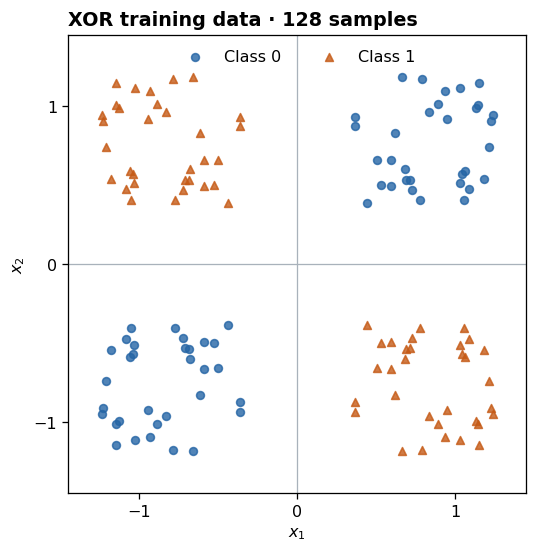

In [14]:
class_colors = ("#2565a5", "#c55a16")
class_markers = ("o", "^")


def plot_points(ax, inputs, labels, **scatter_options):
    for label, (color, marker) in enumerate(zip(class_colors, class_markers)):
        points = inputs[labels.ravel() == label]
        ax.scatter(*points.T, marker=marker, color=color, label=f"Class {label}", **scatter_options)
    ax.set(xlabel="$x_1$", ylabel="$x_2$", xlim=(-1.45, 1.45), ylim=(-1.45, 1.45),
           aspect="equal", xticks=[-1, 0, 1], yticks=[-1, 0, 1])


fig, ax = plt.subplots(figsize=(5.4, 4.7), layout="constrained", dpi=115)
ax.axhline(0, color="#a9b2bb", linewidth=0.8)
ax.axvline(0, color="#a9b2bb", linewidth=0.8)
plot_points(ax, x_train, y_train, s=24, alpha=0.8)
ax.set_title(f"XOR training data · {len(x_train)} samples", loc="left", fontweight="bold")
ax.legend(loc="upper center", ncol=2, frameon=False)
plt.show()

## 10. Linear versus nonlinear classifiers

Check both classifiers on a balanced 16-point subset. The training cell starts from seeded initial weights each time and fits on the full training set. Predict class $1$ when $p\geq 0.5$ and evaluate both splits.

In [15]:
def xor_models():
    baseline = Network(Linear(2, 1, np.random.default_rng(401)), Sigmoid())
    rng = np.random.default_rng(402)
    nonlinear = Network(Linear(2, 8, rng), Tanh(), Linear(8, 1, rng), Sigmoid())
    return {"Linear baseline": baseline, "Tanh network": nonlinear}


labels = y_train.ravel()
subset = np.concatenate((np.flatnonzero(labels == 0)[:8], np.flatnonzero(labels == 1)[:8]))
xor_checks = {}
for name, model in xor_models().items():
    print(name)
    xor_checks[name] = gradient_check(model, BCELoss(), x_train[subset], y_train[subset])

Linear baseline
Relative errors in parameter array order
Array         Entries   Max rel. error  Status
layer1.W            2         3.37e-10  PASS
  1.81e-11
  3.37e-10
layer1.b            1         1.32e-09  PASS
  1.32e-09
Overall PASS (threshold 1e-06)
Tanh network
Relative errors in parameter array order
Array         Entries   Max rel. error  Status
layer1.W           16         2.09e-09  PASS
  5.71e-11  2.27e-10  8.60e-10  1.68e-10  5.29e-11  6.77e-10  4.05e-10  1.56e-10
  1.24e-10  2.09e-09  7.88e-10  2.45e-10  7.71e-10  1.51e-09  1.82e-09  6.80e-11
layer1.b            8         4.14e-09  PASS
  7.70e-11  6.85e-10  6.36e-10  4.14e-09  2.31e-10  2.38e-09  2.04e-09  1.10e-10
layer3.W            8         1.08e-09  PASS
  1.08e-09
  5.05e-11
  5.77e-13
  3.32e-10
  1.59e-11
  7.30e-11
  2.78e-10
  4.00e-11
layer3.b            1         1.16e-09  PASS
  1.16e-09
Overall PASS (threshold 1e-06)


In [16]:
steps, rate = 400, 0.15
models = xor_models()
histories = {name: train(model, x_train, y_train, steps, rate)
             for name, model in models.items()}

print(f"{'Model':<17} {'Params':>6} {'Initial BCE':>12} {'Train BCE':>11} "
      f"{'Train acc.':>11} {'Test BCE':>10} {'Test acc.':>10}")
for name, model in models.items():
    train_prob = model.forward(x_train)
    test_prob = model.forward(x_test)
    history = histories[name]
    train_acc = np.mean((train_prob >= 0.5) == y_train)
    test_acc = np.mean((test_prob >= 0.5) == y_test)
    test_bce = BCELoss().forward(test_prob, y_test)
    n_params = sum(parameter.size for _, parameter, _ in model.parameters_and_grads())
    print(f"{name:<17} {n_params:6d} {history[0]:12.4f} {history[-1]:11.4f} "
          f"{train_acc:11.1%} {test_bce:10.4f} {test_acc:10.1%}")
    assert np.all(np.isfinite(history))
    np.testing.assert_allclose(BCELoss().forward(train_prob, y_train), history[-1],
                               rtol=0, atol=1e-12)
    if name == "Tanh network":
        assert train_acc >= 0.98 and test_acc >= 0.98

Model             Params  Initial BCE   Train BCE  Train acc.   Test BCE  Test acc.
Linear baseline        3       0.7402      0.6931       50.0%     0.6931      50.0%
Tanh network          33       0.6946      0.0590      100.0%     0.0578     100.0%


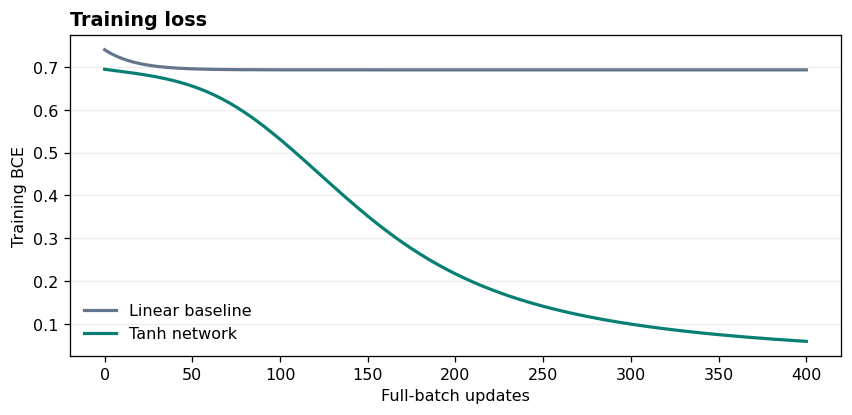

In [17]:
fig, ax = plt.subplots(figsize=(7.3, 3.5), layout="constrained", dpi=115)
for (name, history), color in zip(histories.items(), ("#65758b", "#087f73")):
    ax.plot(np.arange(history.size), history, label=name, color=color, linewidth=2)
ax.set(xlabel="Full-batch updates", ylabel="Training BCE")
ax.set_title("Training loss", loc="left", fontweight="bold")
ax.grid(axis="y", alpha=0.22)
ax.legend(frameon=False)
plt.show()

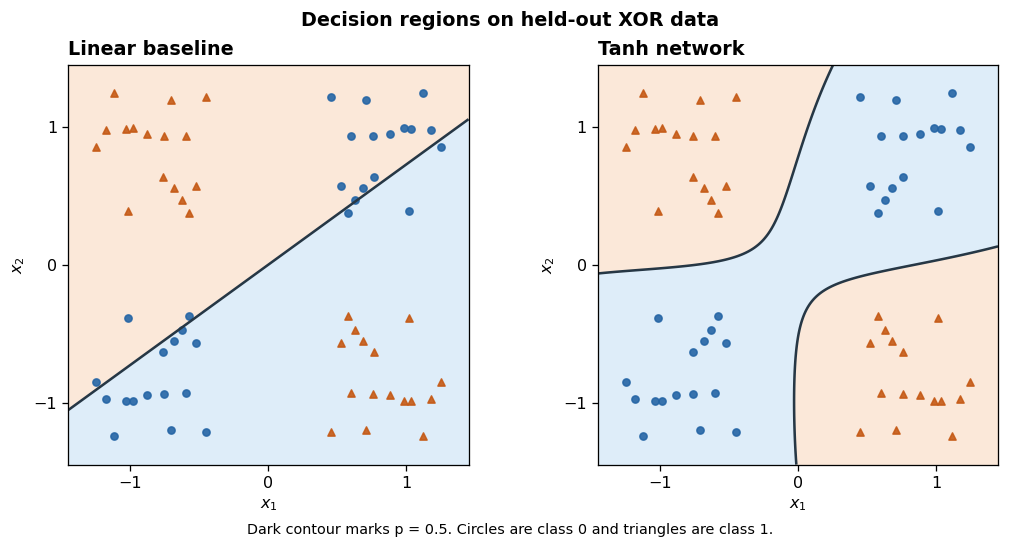

In [18]:
grid_axis = np.linspace(-1.45, 1.45, 241)
xx, yy = np.meshgrid(grid_axis, grid_axis)
grid = np.column_stack((xx.ravel(), yy.ravel()))

fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.65), layout="constrained", dpi=115)
for ax, (name, model) in zip(axes, models.items()):
    probabilities_grid = model.forward(grid).reshape(xx.shape)
    assert probabilities_grid.min() < 0.5 < probabilities_grid.max()
    ax.contourf(xx, yy, probabilities_grid, levels=[0, 0.5, 1],
                colors=["#deedf9", "#fbe8d9"])
    ax.contour(xx, yy, probabilities_grid, levels=[0.5], colors="#263745", linewidths=1.6)
    plot_points(ax, x_test, y_test, s=20, alpha=0.9)
    ax.set_title(name, loc="left", fontweight="bold")
fig.suptitle("Decision regions on held-out XOR data", fontweight="bold")
fig.supxlabel("Dark contour marks p = 0.5. Circles are class 0 and triangles are class 1.",
              fontsize=9)
plt.show()

## 11. Conclusion

Each XOR class contains a pair of opposite points with the origin as its midpoint. The two classes therefore cannot lie on opposite sides of one line. A sigmoid on an affine score has a linear $p=0.5$ boundary, and on this balanced, symmetric dataset the baseline settles near $p=0.5$ and BCE $\log 2$.

The tanh hidden layer combines nonlinear responses and produces a curved boundary. It classifies the held-out points from the same sampling rule. The experiment leaves behavior near the axes largely unconstrained. Clipped BCE has a zero gradient outside its clipping interval, including for an incorrectly saturated prediction.